# Image Compression with the SVD

A grayscale image is just a matrix: an $n\times k$ image is an $n\times k$ matrix $A$ whose entry $a_{ij}$ is the brightness of pixel $(i, j)$, from $0$ (black) to $255$ (white). So everything we know about the SVD applies to pictures.

**Files needed** (put them in the same folder as this notebook):

| image | content | size |
|---|---|---|
| `bridge.jpg` | ink drawing, sharp black and white | $493\times 740$ |
| `logo.jpg` | flat dark shape on white | $1390\times 1393$ |
| `tree.jpg` | detailed engraving | $500\times 500$ |
| `rocks.jpg` | photograph, smooth gray tones and fog | $1680\times 2100$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

bridge shape (493, 740)   min 0.0   max 255.0


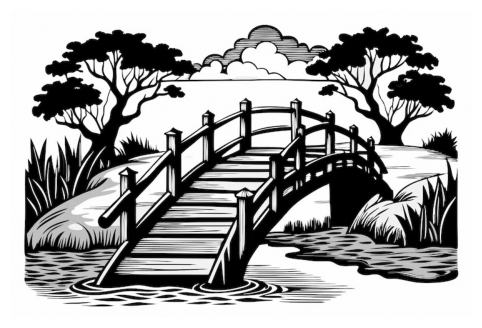

In [2]:
def load(name):
    # plt.imread gives a 2-D array (0..255) for a grayscale JPG; convert to float for linear algebra
    # and clip so every pixel is guaranteed to lie in 0..255
    return np.clip(plt.imread(name).astype(float), 0, 255)

bridge = load("bridge.jpg")
print("bridge shape", bridge.shape, "  min", bridge.min(), "  max", bridge.max())

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(bridge, cmap="gray", vmin=0, vmax=255)
ax.axis("off")
plt.show()

## Part 1. The SVD as a sum of rank-1 layers

Write the reduced SVD $A = U\Sigma V^T$ column by column. With $\mathbf{u}_i$ the columns of $U$ and $\mathbf{v}_i$ the columns of $V$:
$$ A = \sigma_1 \mathbf{u}_1\mathbf{v}_1^T + \sigma_2 \mathbf{u}_2\mathbf{v}_2^T + \dots + \sigma_m \mathbf{u}_m\mathbf{v}_m^T, \qquad m = \min(n, k). $$
Each $\mathbf{u}_i\mathbf{v}_i^T$ is an $n\times k$ matrix of **rank 1** (every row is a multiple of $\mathbf{v}_i^T$). The $\sigma_i$ are sorted largest first, so the first layers carry the most of the picture.

**Compression idea:** keep only the first $r$ layers,
$$ A_r = \sum_{i=1}^{r} \sigma_i \mathbf{u}_i\mathbf{v}_i^T = \underset{n\times r}{U_r}\ \underset{r\times r}{\Sigma_r}\ \underset{r\times k}{V_r^T}. $$
**Why this is a good idea:** the layers are sorted by $\sigma_i$, which measures how much each layer contributes. Keeping the first $r$ layers keeps the biggest contributions and throws away only the smallest ones, so the picture changes as little as possible. As $r$ grows, $A_r$ gets closer to $A$; at $r = \text{rank}(A)$ it is exactly $A$.

In NumPy, $U_r$ is `U[:, :r]`, $\Sigma_r$ is `np.diag(s[:r])`, and $V_r^T$ is `Vt[:r, :]`. Always use `full_matrices=False`: for a $1680\times 2100$ photo the full $U$ and $V$ would be $1680\times1680$ and $2100\times2100$, and we never need the extra columns.

shapes: U (493, 493)   s (493,)   Vt (493, 740)
largest singular values: [99953. 18704. 16950. 16690. 16603.]


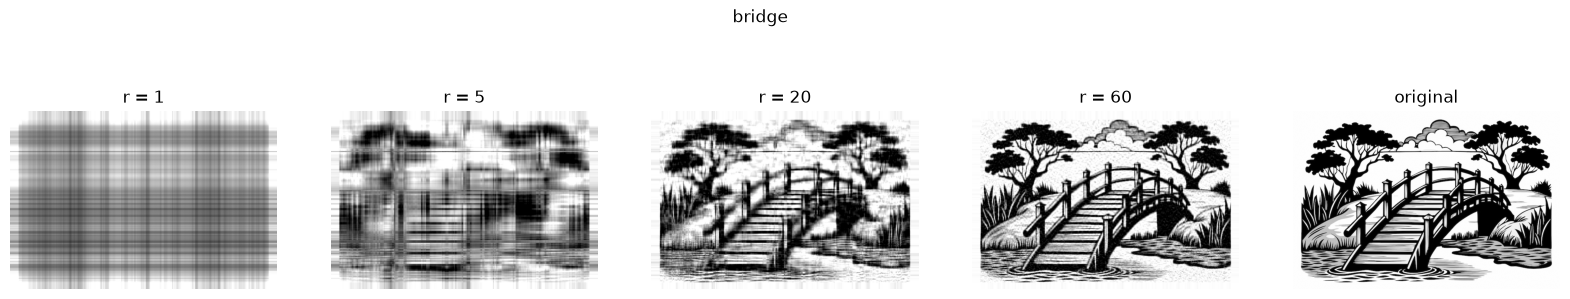

In [3]:
U, s, Vt = np.linalg.svd(bridge, full_matrices=False)
print("shapes: U", U.shape, "  s", s.shape, "  Vt", Vt.shape)
print("largest singular values:", np.round(s[:5]))

def rank_r(U, s, Vt, r):
    # A_r = U_r Sigma_r V_r^T
    return U[:, :r] @ np.diag(s[:r]) @ Vt[:r, :]

def show_ranks(A, U, s, Vt, ranks, title=""):
    # rank-r approximations side by side, then the original
    fig, axes = plt.subplots(1, len(ranks) + 1, figsize=(4 * (len(ranks) + 1), 3.5))
    for j, r in enumerate(ranks):
        axes[j].imshow(rank_r(U, s, Vt, r), cmap="gray", vmin=0, vmax=255)
        axes[j].set_title(f"r = {r}"); axes[j].axis("off")
    axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
    axes[-1].set_title("original"); axes[-1].axis("off")
    fig.suptitle(title, y=1.04)
    plt.show()

show_ranks(bridge, U, s, Vt, [1, 5, 20, 60], "bridge")

## Part 2. How much do we save, and how much do we lose?

**Storage.** The original needs $nk$ numbers. $A_r$ only needs $U_r$, the $r$ values $\sigma_i$, and $V_r$:
$$ \text{storage}(A_r) = nr + r + rk = r(n + k + 1), \qquad \text{compression ratio} = \frac{nk}{r(n+k+1)}. $$
So compression only pays off when $r$ is below the **break-even rank** $\dfrac{nk}{n+k+1}$.

**Error.** Measure it with the Frobenius norm $\|A\|_F = \sqrt{\sum_{i,j} a_{ij}^2}$ (`np.linalg.norm(A)`). Because $U$ and $V$ are orthogonal, $\|A\|_F^2 = \sigma_1^2 + \dots + \sigma_m^2$, and the error is exactly the part we dropped:
$$ \frac{\|A - A_r\|_F}{\|A\|_F} = \sqrt{\frac{\sigma_{r+1}^2 + \dots + \sigma_m^2}{\sigma_1^2 + \dots + \sigma_m^2}}. $$
The fraction $\dfrac{\sigma_1^2 + \dots + \sigma_r^2}{\sum_i \sigma_i^2}$ is called the **energy** kept by $A_r$. We can read off the error **from `s` alone**, without building $A_r$.

**Energy is the number to watch.** Energy kept $= 1 -$ (relative error)$^2$: $99\%$ energy means a relative error of $10\%$. In Part 3 we use energy levels to choose $r$.

In [4]:
n, k = bridge.shape
energy = np.cumsum(s**2) / np.sum(s**2)        # energy[r-1] = energy kept by A_r

print("  r   ratio   rel. error (direct)   rel. error (from s)")
for r in [5, 20, 60, 150]:
    Ar = rank_r(U, s, Vt, r)
    direct  = np.linalg.norm(bridge - Ar) / np.linalg.norm(bridge)
    from_s  = np.sqrt(1 - energy[r - 1])
    ratio   = n * k / (r * (n + k + 1))
    print(f"{r:4d}  {ratio:5.1f}x       {direct:.4f}              {from_s:.4f}")

print("\nbreak-even rank nk/(n+k+1) =", round(n * k / (n + k + 1)))

  r   ratio   rel. error (direct)   rel. error (from s)
   5   59.1x       0.4192              0.4192
  20   14.8x       0.2657              0.2657
  60    4.9x       0.1505              0.1505
 150    2.0x       0.0690              0.0690

break-even rank nk/(n+k+1) = 296


## Part 3. Choosing $r$: reading the singular value plot

There is no single "correct" $r$. It depends on what the picture is for. But the plot of $\sigma_i$ on a **log scale** tells you a lot. Plot $\sigma_i / \sigma_1$ (so the first value is $1$ and different images can be compared).

**Practical tip:** plot only the first $150$ or so values. Drawings with blank borders have their last singular values at round-off level ($10^{-13}$ and smaller). Plotting all of them squashes the interesting part of the curve.

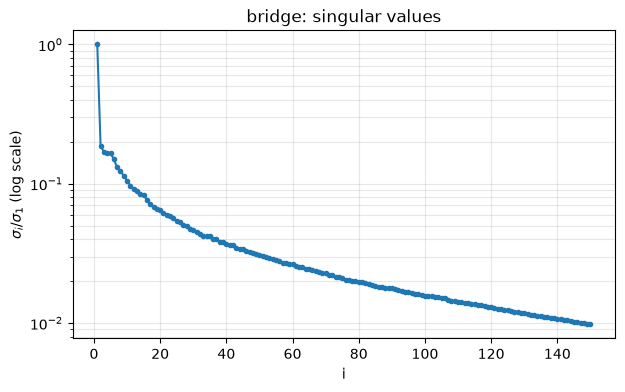

sigma_i / sigma_1 for i = 1..8: [1.    0.187 0.17  0.167 0.166 0.15  0.131 0.123]


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, 151), s[:150] / s[0], ".-")
ax.set_xlabel("i"); ax.set_ylabel(r"$\sigma_i / \sigma_1$ (log scale)")
ax.set_title("bridge: singular values")
ax.grid(True, which="both", alpha=0.3)
plt.show()

print("sigma_i / sigma_1 for i = 1..8:", np.round(s[:8] / s[0], 3))

**How to read the curve.** It has three zones:

| zone | what you see in the plot | what those layers add to the picture |
|---|---|---|
| **head** | the first few $\sigma$'s, falling steeply | overall brightness and the big shapes |
| **elbow** (or **knee**) | where the steep fall bends into a slow decline | after this point, the picture is recognizable |
| **tail** | long, slowly falling part | edges, fine texture, and noise |

- $\sigma_1$ is always far ahead. Layer 1 is roughly the **average brightness** pattern (look at $r = 1$ in Part 1).
- **The elbow is the smallest sensible $r$.** Cutting before it loses whole shapes. Cutting right at it gives a rough but recognizable picture.
- **The tail decides the price of quality.** A tail that drops fast means a few extra layers give a sharp picture: great compression. A **flat, heavy tail** (like the bridge's) means detail is spread over hundreds of layers. Sharp edges and fine lines are expensive.
- **Energy thresholds** turn this into numbers. The most common choices are $90\%$ (rough), $99\%$ (good), and $99.9\%$ (hard to tell from the original). Always check $r$ is well below the break-even rank.
- **Then look!** The final judge is your eye: show $A_r$ next to the original, and zoom in on fine detail.

Now mark the energy thresholds on the curve and look at the pictures:

r for 90%, 99%, 99.9% energy: [13, 104, 260]    break-even: 296


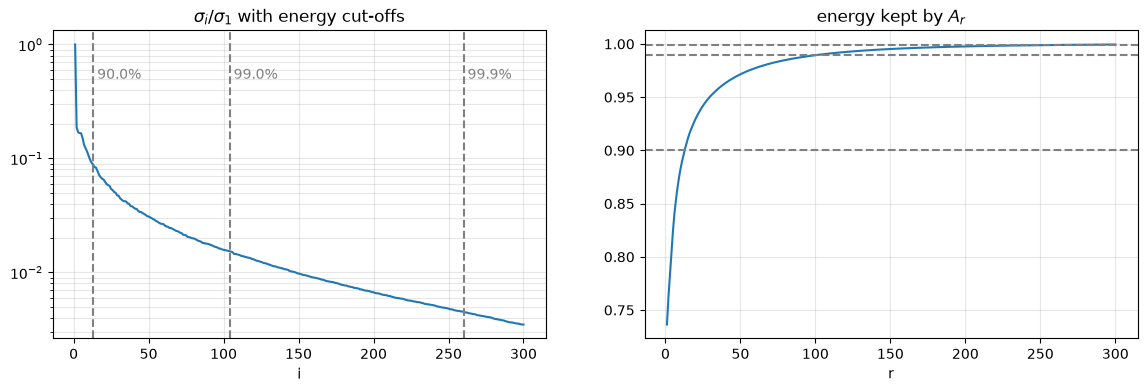

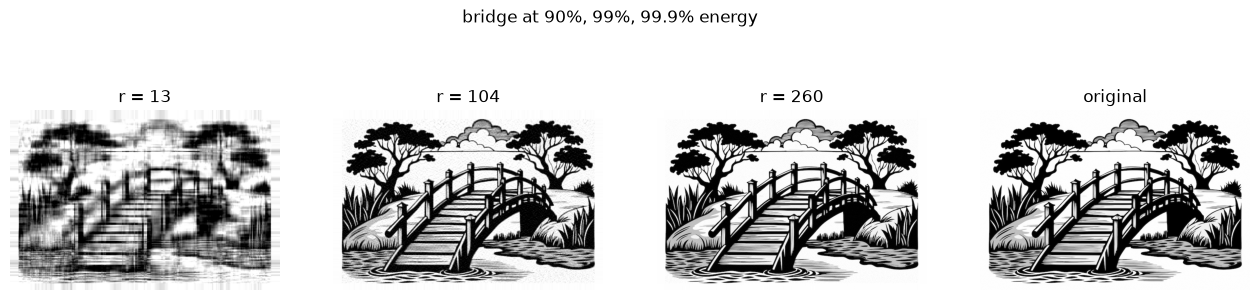

In [6]:
def r_for_energy(s, level):
    # smallest r with energy >= level. argmax returns the FIRST index where the condition is True;
    # + 1 because Python counts from 0 but r counts layers from 1.
    energy = np.cumsum(s**2) / np.sum(s**2)
    return int(np.argmax(energy >= level)) + 1

levels = [0.90, 0.99, 0.999]
r_marks = [r_for_energy(s, lev) for lev in levels]
print("r for 90%, 99%, 99.9% energy:", r_marks, "   break-even:", round(n * k / (n + k + 1)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].semilogy(np.arange(1, 301), s[:300] / s[0])
axes[1].plot(np.arange(1, 301), energy[:300])
for lev, r in zip(levels, r_marks):
    axes[0].axvline(r, ls="--", color="gray")
    axes[0].text(r, 0.5, f" {lev:.1%}", color="gray")
    axes[1].axhline(lev, ls="--", color="gray")
axes[0].set_title(r"$\sigma_i / \sigma_1$ with energy cut-offs"); axes[0].set_xlabel("i")
axes[1].set_title("energy kept by $A_r$"); axes[1].set_xlabel("r")
axes[0].grid(True, which="both", alpha=0.3)
axes[1].grid(True, which="both", alpha=0.3)
plt.show()

show_ranks(bridge, U, s, Vt, r_marks, "bridge at 90%, 99%, 99.9% energy")

**Bridge verdict.** At $90\%$ ($r = 13$) the picture is a blurry outline; at $99\%$ ($r = 104$) it looks good but the ratio is only about $3\times$. The heavy tail of a black-and-white line drawing makes it a **hard** image for the SVD.

## Part 4. A second example: the logo (energy of the ink)

The logo is a simple shape: one flat dark color on white, with smooth edges and no texture. It compresses very well. But it also shows a trap: **when most of the picture is white background, the energy of $A$ is misleading**, and we should measure the energy of the **ink**, $255 - A$, instead.

Load the logo and look at it:

logo shape (1390, 1393)   min 49.0   max 255.0
fraction of white background (pixels > 240): 0.63


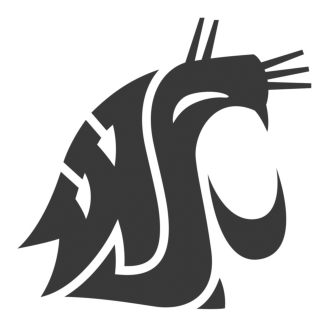

In [7]:
logo = load("logo.jpg")
print("logo shape", logo.shape, "  min", logo.min(), "  max", logo.max())
print("fraction of white background (pixels > 240):", round(np.mean(logo > 240), 2))

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(logo, cmap="gray", vmin=0, vmax=255)
ax.axis("off")
plt.show()

First compare its singular values with the bridge's on **one** plot.

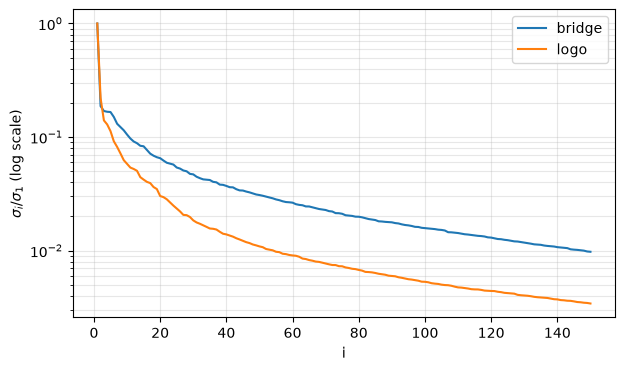

logo: r for 90%, 99%, 99.9% energy: [2, 24, 152]


In [8]:
Ul, sl, Vtl = np.linalg.svd(logo, full_matrices=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, 151), s[:150] / s[0], label="bridge")
ax.semilogy(np.arange(1, 151), sl[:150] / sl[0], label="logo")
ax.set_xlabel("i"); ax.set_ylabel(r"$\sigma_i / \sigma_1$ (log scale)")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.show()

print("logo: r for 90%, 99%, 99.9% energy:", [r_for_energy(sl, lev) for lev in levels])

The head and elbow look much like the bridge's, but the logo's **tail** falls about $3\times$ lower: once the big shapes are in, there is very little fine detail left. So $99\%$ energy needs only $r = 24$ (bridge: $104$), on an image with over $5\times$ as many pixels.

**But be careful with the $90\%$ level:** it says $r = 2$. Look at $A_2$ below: it is only a blur of stripes.

About $63\%$ of the logo is white background ($255$), so the energy $\sum a_{ij}^2$ is mostly **background**. The first layers get the background right and already collect most of the energy, before the shape appears. Energy percentages are **too optimistic** for images with a large white background.

**Fix: measure the ink, not the paper.** Compress $B = 255 - A$ (white becomes $0$, the shape becomes positive), then turn back with $A \approx 255 - B_r$. Now the energy only counts the shape, and the $r$ values are more honest.

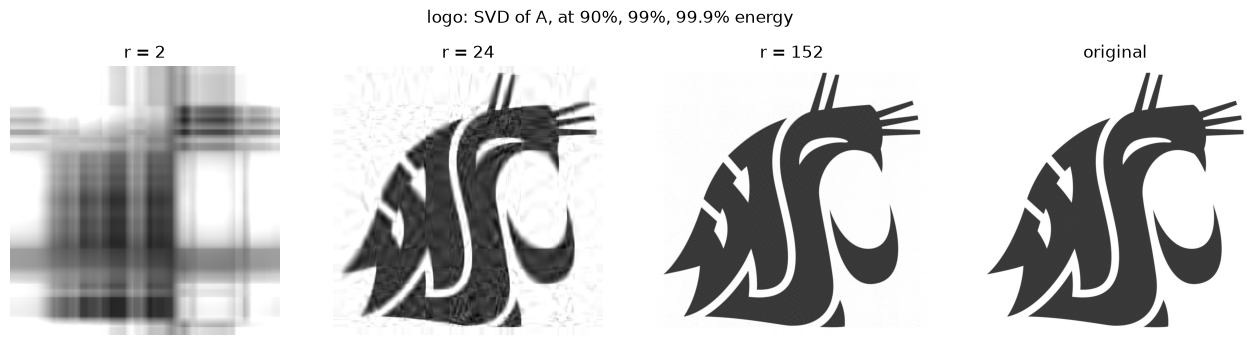

255 - logo: r for 90%, 99%, 99.9% energy: [8, 60, 283]


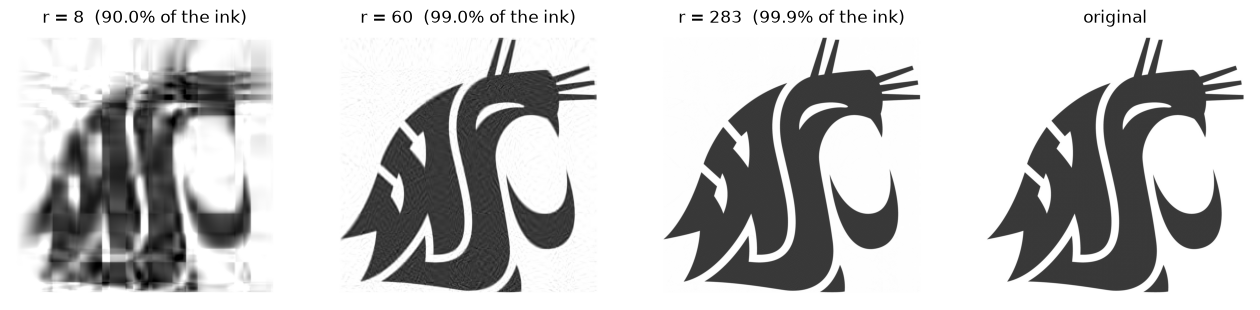

compression ratio at 99% energy of A:      r = 24    29.0 x
compression ratio at 99% energy of the ink: r = 60    11.6 x


In [9]:
show_ranks(logo, Ul, sl, Vtl, [r_for_energy(sl, lev) for lev in levels], "logo: SVD of A, at 90%, 99%, 99.9% energy")

B = 255 - logo                                   # ink, not paper
Ub, sb, Vtb = np.linalg.svd(B, full_matrices=False)
rb = [r_for_energy(sb, lev) for lev in levels]
print("255 - logo: r for 90%, 99%, 99.9% energy:", rb)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for j, r in enumerate(rb):
    axes[j].imshow(255 - rank_r(Ub, sb, Vtb, r), cmap="gray", vmin=0, vmax=255)
    axes[j].set_title(f"r = {r}  ({levels[j]:.1%} of the ink)"); axes[j].axis("off")
axes[-1].imshow(logo, cmap="gray", vmin=0, vmax=255); axes[-1].set_title("original"); axes[-1].axis("off")
plt.show()

n, k = logo.shape
r99 = r_for_energy(sl, 0.99)
print("compression ratio at 99% energy of A:      r =", r99, "  ", round(n * k / (r99 * (n + k + 1)), 1), "x")
print("compression ratio at 99% energy of the ink: r =", rb[1], "  ", round(n * k / (rb[1] * (n + k + 1)), 1), "x")

**Lessons from the logo:**
- Flat regions and smooth edges compress very well: about $29\times$ at $99\%$ energy. The shape is clear, with some ripples near the edges; at $99.9\%$ ($r = 152$) it is hard to tell from the original.
- A large white background inflates $\sigma_1$ and the energy, so a low threshold like $90\%$ can point to a useless $r$. Measuring $255 - A$ (the ink) gives a stricter, more honest $r$.

### Summary

| quantity | formula | NumPy |
|---|---|---|
| reduced SVD | $A = U\Sigma V^T$ | `U, s, Vt = np.linalg.svd(A, full_matrices=False)` |
| rank-$r$ approximation | $A_r = U_r\Sigma_rV_r^T$ | `U[:, :r] @ np.diag(s[:r]) @ Vt[:r, :]` |
| storage of $A_r$ | $r(n+k+1)$ | |
| break-even rank | $nk/(n+k+1)$ | |
| **energy** kept by $A_r$ | $\sum_{i\le r}\sigma_i^2 / \sum_i \sigma_i^2$ | `np.cumsum(s**2) / np.sum(s**2)` |
| **ink** (large white background) | $B = 255 - A$, compress $B$, then $A \approx 255 - B_r$ | `B = 255 - A`, then the SVD of `B` |
| energy of the ink | same formula, with the $\sigma_i$ of $B$ | `r_for_energy(sb, 0.99)` with `sb` from the SVD of `B` |
| relative error | $\sqrt{1 - \text{energy}}$ | `np.linalg.norm(A - Ar) / np.linalg.norm(A)` |
| smallest $r$ for an energy level | | `r_for_energy(s, 0.99)` |

**Choosing $r$, step by step:** (1) plot $\sigma_i/\sigma_1$ with `ax.semilogy`, first $\sim 150$ values; (2) find the elbow, the smallest sensible $r$; (3) compute $r$ for $90\%$, $99\%$, $99.9\%$ energy, on $255 - A$ if there is a big white background; (4) check against the break-even rank; (5) look at the pictures and decide.

## Exercises

**Syntax you will need:**

| task | NumPy / Matplotlib |
|---|---|
| read a grayscale image as a float matrix (clipped to $0..255$) | `A = load("tree.jpg")` |
| shape $n\times k$ | `n, k = A.shape` |
| reduced SVD | `U, s, Vt = np.linalg.svd(A, full_matrices=False)` |
| first $r$ columns of $U$ / first $r$ rows of $V^T$ | `U[:, :r]` / `Vt[:r, :]` |
| first $r$ singular values / as a diagonal matrix | `s[:r]` / `np.diag(s[:r])` |
| matrix product | `A @ B` |
| numbers $1, 2, \dots, 150$ | `np.arange(1, 151)` |
| one plot | `fig, ax = plt.subplots(figsize=(7, 4))` |
| a row of $4$ plots | `fig, axes = plt.subplots(1, 4, figsize=(16, 4))`, then `axes[0]`, `axes[1]`, ... |
| log-scale plot (with a label for the legend) | `ax.semilogy(x, y, label="tree")` |
| show an image in panel `j` | `axes[j].imshow(A, cmap="gray", vmin=0, vmax=255)` |
| title, axis label (one plot) | `ax.set_title("tree")`, `ax.set_xlabel("i")` |
| title of panel `j` (a row of plots) | `axes[j].set_title("r = 20")` |
| legend, grid (one plot) | `ax.legend()`, `ax.grid(True, which="both", alpha=0.3)` |
| hide the axes of panel `j` | `axes[j].axis("off")` |
| draw the figure | `plt.show()` |

**Exercise 1 (tree).**

(a) Read `tree.jpg` into a matrix $A$. What is its size $n\times k$?

(b) Compute the reduced SVD of $A$. Give the shapes of `U`, `s`, `Vt`.

(c) Plot $\sigma_i / \sigma_1$ for $i = 1, \dots, 150$ with `ax.semilogy`. Where is the elbow, roughly?

(d) Compute $A_r = U_r\Sigma_rV_r^T$ for $r = 10, 40, 100$. Show them in one row of $4$ panels: the three approximations and the original.

(e) Which $r$ looks good enough to you? Try other values if needed. For your $r$, compute the compression ratio $\dfrac{nk}{r(n+k+1)}$.

In [10]:
# Exercise 1

**Exercise 2 (rocks).**

(a)–(e) Repeat Exercise 1 for `rocks.jpg`. (It is large: the SVD takes a few seconds, so compute it only once.)

(f) Plot the two curves $\sigma_i / \sigma_1$ (tree and rocks) on **one** `ax.semilogy` plot. Which image needs a smaller $r$ to look good? Explain using what the images look like (smooth tones vs. sharp edges and fine detail).

In [11]:
# Exercise 2